# 3_solar_energy

This notebook estimates deployable PV area and solar-energy-related KPIs for the BIPV facade layouts created in notebook `2_generate_bipv_retrofit.ipynb`.

It integrates:
- notebook 2 generation outputs
- notebook 1 metric scale predictions
- metadata geometry (`EGID`, `EDID`, `version`, `view_line`, `facade_pt`)
- Sonnenfassade facade irradiation data from a `.gpkg` file in `external/`

Main steps:
1. load layout outputs and normalize identifiers
2. reconstruct a shared facade key (`image_stem`)
3. match metadata facades to Sonnenfassade segments using `EGID` and geometry
4. merge solar irradiation with PV layouts
5. compute PV area, installed capacity, and annual energy
6. visualize and export results

In [1]:
# Standard library
from pathlib import Path

# Data
import numpy as np
import pandas as pd

# Geo
import geopandas as gpd
from shapely import wkt

# Imaging / plotting
import cv2
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [2]:
# -----------------------------------------------------------------------------
# Paths (aligned with notebooks 0–2)
# -----------------------------------------------------------------------------

REPO_ROOT = Path("..").resolve()

OUTPUT2_DIR = REPO_ROOT / "outputs" / "2_generated_bipv_facades"
OUTPUT1_DIR = REPO_ROOT / "outputs" / "1_vlm_preds"
EXTERNAL_DIR = REPO_ROOT / "external"
DATA_DIR = REPO_ROOT / "data" / "demo" / "input"

RUN_LOG_CSV = OUTPUT2_DIR / "tables" / "generation_runtime_log.csv"
VLM_CSV = OUTPUT1_DIR / "vlm_predictions.csv"
METADATA_CSV = DATA_DIR / "metadata.csv"

OUTPUT3_DIR = REPO_ROOT / "outputs" / "3_solar_energy"
TABLES_DIR = OUTPUT3_DIR / "tables"

TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("RUN_LOG:", RUN_LOG_CSV)
print("Sonnenfassade dir:", EXTERNAL_DIR)

RUN_LOG: D:\facade2dim\image2bipv\outputs\2_generated_bipv_facades\tables\generation_runtime_log.csv
Sonnenfassade dir: D:\facade2dim\image2bipv\external


In [3]:
# -----------------------------------------------------------------------------
# Repository-relative paths
# -----------------------------------------------------------------------------

REPO_ROOT = Path("..").resolve()

DATA_DIR = REPO_ROOT / "data" / "demo" / "input"
OUTPUT1_DIR = REPO_ROOT / "outputs" / "1_vlm_preds"
OUTPUT2_DIR = REPO_ROOT / "outputs" / "2_generated_bipv_facades"
OUTPUT3_DIR = REPO_ROOT / "outputs" / "3_solar_energy"
EXTERNAL_DIR = REPO_ROOT / "external"

METADATA_CSV = DATA_DIR / "metadata.csv"
VLM_CSV = OUTPUT1_DIR / "vlm_predictions.csv"
RUN_LOG_CSV = OUTPUT2_DIR / "tables" / "generation_runtime_log.csv"

TABLES_DIR = OUTPUT3_DIR / "tables"
PLOTS_DIR = OUTPUT3_DIR / "plots"

for folder in [OUTPUT3_DIR, TABLES_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("REPO_ROOT:", REPO_ROOT)
print("METADATA_CSV:", METADATA_CSV)
print("VLM_CSV:", VLM_CSV)
print("RUN_LOG_CSV:", RUN_LOG_CSV)
print("EXTERNAL_DIR:", EXTERNAL_DIR)

REPO_ROOT: D:\facade2dim\image2bipv
METADATA_CSV: D:\facade2dim\image2bipv\data\demo\input\metadata.csv
VLM_CSV: D:\facade2dim\image2bipv\outputs\1_vlm_preds\vlm_predictions.csv
RUN_LOG_CSV: D:\facade2dim\image2bipv\outputs\2_generated_bipv_facades\tables\generation_runtime_log.csv
EXTERNAL_DIR: D:\facade2dim\image2bipv\external


In [4]:
# -----------------------------------------------------------------------------
# Runtime configuration
# -----------------------------------------------------------------------------

PANEL_WIDTH_M = 1.0
PANEL_HEIGHT_M = 1.7
PANEL_STC_W = 400
PERFORMANCE_RATIO = 0.80

SHOW_VISUALS = True
N_PREVIEW_ROWS = 6

RESULTS_CSV = TABLES_DIR / "solar_kpi_results.csv"
MATCHED_METADATA_CSV = TABLES_DIR / "matched_metadata_to_sonnenfassade.csv"

In [5]:
# -----------------------------------------------------------------------------
# Helpers
# -----------------------------------------------------------------------------

def normalize_version_token(value) -> str:
    if pd.isna(value):
        return "v1"
    s = str(value).strip().lower()
    if not s:
        return "v1"
    if s.startswith("v"):
        body = s[1:]
        try:
            return f"v{int(float(body))}"
        except Exception:
            return s
    try:
        return f"v{int(float(s))}"
    except Exception:
        return s


def stem_from_image_name(image_name: str) -> str:
    return Path(str(image_name)).stem


def maybe_int_string(value):
    if pd.isna(value):
        return None
    try:
        return str(int(float(value)))
    except Exception:
        s = str(value).strip()
        return s if s else None


def find_first_existing_col(df: pd.DataFrame, candidates: list[str]):
    mapping = {str(c).lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in mapping:
            return mapping[cand.lower()]
    return None


def parse_wkt_safe(value):
    if pd.isna(value):
        return None
    if hasattr(value, "geom_type"):
        return value
    s = str(value).strip()
    if not s or s.lower() in {"none", "nan", "null"}:
        return None
    try:
        return wkt.loads(s)
    except Exception:
        return None


def add_image_keys(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    image_col = find_first_existing_col(out, ["image_name", "selected_image", "filename", "file_name"])
    egid_col = find_first_existing_col(out, ["EGID", "gwr_egid"])
    edid_col = find_first_existing_col(out, ["EDID", "edid"])
    version_col = find_first_existing_col(out, ["version", "facade_version", "view_version"])

    if image_col is not None:
        out["image_stem"] = out[image_col].astype(str).map(stem_from_image_name)
    elif egid_col is not None and edid_col is not None:
        version_series = out[version_col].map(normalize_version_token) if version_col is not None else "v1"
        out["image_stem"] = (
            out[egid_col].map(maybe_int_string) + "_"
            + out[edid_col].map(maybe_int_string) + "_"
            + version_series.astype(str)
        )
    else:
        raise ValueError("Need either image_name/selected_image or EGID+EDID to build image_stem.")

    out["EGID_norm"] = (
        out[egid_col].map(maybe_int_string)
        if egid_col is not None
        else out["image_stem"].str.extract(r"^(\d+)_")[0]
    )

    out["EDID_norm"] = (
        out[edid_col].map(maybe_int_string)
        if edid_col is not None
        else out["image_stem"].str.extract(r"^\d+_(\d+)_")[0]
    )

    out["version_token"] = (
        out[version_col].map(normalize_version_token)
        if version_col is not None
        else out["image_stem"].str.extract(r"_(v[^_]+)$")[0].fillna("v1")
    )

    return out


def read_rgb(path: str | Path):
    return np.array(Image.open(path).convert("RGB"))


def show_images_row(items, figsize_scale=4.5):
    plt.figure(figsize=(figsize_scale * len(items), figsize_scale))
    for i, (title, img) in enumerate(items, start=1):
        plt.subplot(1, len(items), i)
        if isinstance(img, (str, Path)):
            arr = read_rgb(img)
        else:
            arr = img
        plt.imshow(arr, cmap="gray" if getattr(arr, "ndim", 3) == 2 else None)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [6]:
# -----------------------------------------------------------------------------
# Locate Sonnenfassade .gpkg
# -----------------------------------------------------------------------------

gpkg_files = sorted(EXTERNAL_DIR.glob("**/*.gpkg"))
if not gpkg_files:
    raise FileNotFoundError("No .gpkg file found under external/")

SONNENFASSADE_GPKG = gpkg_files[0]
print("Using Sonnenfassade file:", SONNENFASSADE_GPKG)

gdf = gpd.read_file(SONNENFASSADE_GPKG)
display(gdf.head())
print("Sonnenfassade CRS:", gdf.crs)
print("Sonnenfassade columns:", list(gdf.columns))

Using Sonnenfassade file: D:\facade2dim\image2bipv\external\sonnenfassade\SOLKAT_FASS.gpkg


c:\Users\durana\AppData\Local\miniforge3\envs\solar\Lib\site-packages\pyogrio\geopandas.py:275: UserWarning: More than one layer found in 'SOLKAT_FASS.gpkg': 'SOLKAT_CH_FASS' (default), 'EIGNUNG_FASS', 'SB_OBJEKTART'. Specify layer parameter to avoid this warning.
  result = read_func(


,FF_UID,FF_NUMMER,DATUM_ERSTELLUNG,DATUM_AENDERUNG,SB_UUID,SB_OBJEKTART,SB_DATUM_ERSTELLUNG,SB_DATUM_AENDERUNG,KLASSE,FLAECHE,AUSRICHTUNG,MSTRAHLUNG,GSTRAHLUNG,STROMERTRAG,STROMERTRAG_SOMMERHALBJAHR,STROMERTRAG_WINTERHALBJAHR,WAERMEERTRAG,DUSCHGAENGE,DG_HEIZUNG,DG_WAERMEBEDARF,BEDARF_WARMWASSER,BEDARF_HEIZUNG,FLAECHE_KOLLEKTOREN,VOLUMEN_SPEICHER,GWR_EGID,geometry
0,14496123,3,2018-04-15 11:15:50+00:00,2018-04-15 11:15:50+00:00,{5ED1EEE6-0F25-48A9-B29C-614770D4AF4C},1,2017-02-09 00:00:00+00:00,2017-04-19 12:09:11+00:00,1,126.436141,-131,410,51839,8294,5969.0,2325.0,0,0,0,0,0,0,0.0,0,-9999,"MULTILINESTRING ((2584999.35 1149635.71, 25850..."
1,14496125,5,2018-04-15 11:15:52+00:00,2018-04-15 11:15:52+00:00,{5ED1EEE6-0F25-48A9-B29C-614770D4AF4C},1,2017-02-09 00:00:00+00:00,2017-04-19 12:09:11+00:00,4,110.074971,-41,1121,123394,19743,10039.0,9704.0,0,0,0,0,0,0,0.0,0,-9999,"MULTILINESTRING ((2585006.72 1149617.789, 2584..."
2,14622649,1,2018-03-23 11:20:35+00:00,2018-03-23 11:20:35+00:00,{CC2BF52D-AF1B-4BFB-976F-5C0DE393C9C0},1,2017-02-09 00:00:00+00:00,2017-02-09 00:00:00+00:00,2,31.326296,16,650,20362,3258,2181.0,1077.0,0,0,0,0,0,0,0.0,0,-9999,"MULTILINESTRING ((2548897.288 1134610.543, 254..."
3,14622650,2,2018-03-23 11:20:36+00:00,2018-03-23 11:20:36+00:00,{CC2BF52D-AF1B-4BFB-976F-5C0DE393C9C0},1,2017-02-09 00:00:00+00:00,2017-02-09 00:00:00+00:00,1,24.727865,106,541,13378,2140,1554.0,586.0,0,0,0,0,0,0,0.0,0,-9999,"MULTILINESTRING ((2548871.22 1134618.016, 2548..."
4,14622651,3,2018-03-23 11:20:36+00:00,2018-03-23 11:20:36+00:00,{CC2BF52D-AF1B-4BFB-976F-5C0DE393C9C0},1,2017-02-09 00:00:00+00:00,2017-02-09 00:00:00+00:00,1,53.990966,-164,311,16791,2687,1787.0,900.0,0,0,0,0,0,0,0.0,0,-9999,"MULTILINESTRING ((2548873.373 1134625.524, 254..."


Sonnenfassade CRS: EPSG:2056
Sonnenfassade columns: ['FF_UID', 'FF_NUMMER', 'DATUM_ERSTELLUNG', 'DATUM_AENDERUNG', 'SB_UUID', 'SB_OBJEKTART', 'SB_DATUM_ERSTELLUNG', 'SB_DATUM_AENDERUNG', 'KLASSE', 'FLAECHE', 'AUSRICHTUNG', 'MSTRAHLUNG', 'GSTRAHLUNG', 'STROMERTRAG', 'STROMERTRAG_SOMMERHALBJAHR', 'STROMERTRAG_WINTERHALBJAHR', 'WAERMEERTRAG', 'DUSCHGAENGE', 'DG_HEIZUNG', 'DG_WAERMEBEDARF', 'BEDARF_WARMWASSER', 'BEDARF_HEIZUNG', 'FLAECHE_KOLLEKTOREN', 'VOLUMEN_SPEICHER', 'GWR_EGID', 'geometry']


In [7]:
# -----------------------------------------------------------------------------
# Load notebook 2, notebook 1, and metadata inputs
# -----------------------------------------------------------------------------

generation_log = pd.read_csv(RUN_LOG_CSV)
generation_log = add_image_keys(generation_log)

if "variant_name" in generation_log.columns and "variant" not in generation_log.columns:
    generation_log["variant"] = generation_log["variant_name"]

if "generator_type" in generation_log.columns and "generator" not in generation_log.columns:
    generation_log["generator"] = generation_log["generator_type"]

panel_layouts = (
    generation_log[
        [c for c in [
            "image_name",
            "image_stem",
            "EGID_norm",
            "EDID_norm",
            "version_token",
            "variant",
            "generator",
            "panel_count",
            "mask_path",
            "overlay_path",
            "generated_rectified_path",
            "generated_perspective_path",
        ] if c in generation_log.columns]
    ]
    .dropna(subset=["image_stem", "panel_count"])
    .reset_index(drop=True)
)

vlm_df = pd.read_csv(VLM_CSV)
vlm_df = add_image_keys(vlm_df)

meta_df = pd.read_csv(METADATA_CSV, sep=";")
facade_meta = add_image_keys(meta_df)

display(panel_layouts.head())
display(vlm_df.head())
display(facade_meta.head())

,image_name,image_stem,EGID_norm,EDID_norm,version_token,variant,generator,panel_count,mask_path,overlay_path,generated_rectified_path,generated_perspective_path
0,151360_0_v1.jpg,151360_0_v1,151360,0,v1,automatic_gemini,gemini,8,D:\facade2dim\image2bipv\outputs\2_generated_b...,D:\facade2dim\image2bipv\outputs\2_generated_b...,D:\facade2dim\image2bipv\outputs\2_generated_b...,D:\facade2dim\image2bipv\outputs\2_generated_b...


,facade_id,facade_version,selected_image,rectified_image,provider,model_name,raw_response,error_message,parse_status,pred_floors,pred_height_m,pred_width_m,runtime_s,image_stem,EGID_norm,EDID_norm,version_token
0,142728_0,v1,142728_0_v1.jpg,142728_0_v1_rectified.png,openai,gpt-4o,"2, 6, 15",NaN,ok,2,6.0,15.0,1.937140,142728_0_v1,142728,0,v1
1,142767_0,v1,142767_0_v1.jpg,142767_0_v1_rectified.png,openai,gpt-4o,"1, 4, 12",NaN,ok,1,4.0,12.0,2.738097,142767_0_v1,142767,0,v1
2,147978_0,v1,147978_0_v1.jpg,147978_0_v1_rectified.png,openai,gpt-4o,"5, 15, 10",NaN,ok,5,15.0,10.0,2.774974,147978_0_v1,147978,0,v1
3,148455_0,v2,148455_0_v2.jpg,148455_0_v2_rectified.png,openai,gpt-4o,"6, 18, 20",NaN,ok,6,18.0,20.0,2.919499,148455_0_v2,148455,0,v2
4,149099_0,v1,149099_0_v1.jpg,149099_0_v1_rectified.png,openai,gpt-4o,"6, 18, 20",NaN,ok,6,18.0,20.0,2.913607,149099_0_v1,149099,0,v1


,index,SQLindex,EGID,EDID,EGAID,GGDENR,GGDENAME,GBAUJ,GAREA,GASTW,GEBF,GKLAS,address,DKOD,DKOD_wgs,GKOD,GKOD_wgs,be_overlap,street_and_number,gsv_status,gsv_wgs,gsv_src,gsv_date,building_pt,entrance_pt,gsv_pt,view_line,view_line_length,geometry_sf,geometry_block,block_height,e_to_sf,e_to_block,base_geometry_src,facade_pt,facade_distance,geometry,pitch_1,pitch_x,heading,floors_seen,version,url_1,url_2,url_3,image_stem,EGID_norm,EDID_norm,version_token
0,101.0,101,149099,0,100124126,261,ZÃ¼rich,1971,172,9,1548,1122,"Brauerstrasse 31, 8004 ZÃ¼rich","('2682193.621', '1247993.666')","(47.377651336316504, 8.527012640395744)","('2682194.12', '1247992.421')","(47.37764007730887, 8.527019018540532)",False,Brauerstrasse 31,OK,"(47.3777704129046, 8.527135085401419)",Â© Google,01.09.2024,POINT (2682194.1206169124 1247992.4221392379),POINT (2682193.621616911 1247993.6671392377),POINT (2682202.6842748434 1248007.0333190532),LINESTRING (2682202.6842748434 1248007.0333190...,16.148886,POLYGON ((2682193.1142980177 1248001.900354660...,POLYGON ((2682193.2118274304 1248001.731940449...,20.4,1.231431,1.327520,BLOCK,POINT (2682197.1213658983 1247998.8287898945),9.912631,POLYGON ((2682193.2118274304 1248001.731940449...,32.231787,39.769646,214.138410,7.5,1,"https://www.google.com/maps/@47.377775,8.52714...","https://www.google.com/maps/@47.3778288,8.5270...","https://www.google.com/maps/@47.3777217,8.5272...",149099_0_v1,149099,0,v1
1,79.0,79,151360,0,100144443,261,ZÃ¼rich,1976,164,4,656,1122,"BrÃ¼derhofweg 31, 8057 ZÃ¼rich","('2683045.647', '1250516.67')","(47.40023471391282, 8.538761834650565)","('2683045.753', '1250516.865')","(47.400236454240805, 8.538763274902157)",False,BrÃ¼derhofweg 31,OK,"(47.40029725318168, 8.538956434954304)",Â© Google,01.06.2022,POINT (2683045.7536167996 1250516.866139768),POINT (2683045.6476167995 1250516.6711397637),POINT (2683060.2388803815 1250523.829718847),LINESTRING (2683060.2388803815 1250523.8297188...,16.252699,"POLYGON ((2683042.469244732 1250506.954625113,...",POLYGON ((2683054.7076358977 1250515.043730683...,12.1,0.654904,0.258812,BLOCK,POINT (2683051.6690003406 1250519.6252739294),9.545690,POLYGON ((2683054.7076358977 1250515.043730683...,9.903944,21.012656,243.867098,3.5,1,"https://www.google.com/maps/@47.400297,8.53895...","https://www.google.com/maps/@47.4002216,8.5390...","https://www.google.com/maps/@47.4003753,8.5388...",151360_0_v1,151360,0,v1
2,104.0,104,142728,0,100124972,261,ZÃ¼rich,1988,220,5,1100,1122,"Speerstrasse 4, 8038 ZÃ¼rich","('2682103.396', '1244176.397')","(47.3433322392964, 8.525118248831385)","('2682103.761', '1244176.697')","(47.34333489188743, 8.525123133303147)",False,Speerstrasse 4,OK,"(47.34343397894494, 8.525316539321336)",Â© Google,01.07.2022,POINT (2682103.7616180223 1244176.698138053),POINT (2682103.3966180226 1244176.3981380512),POINT (2682118.2233168026 1244187.9160561743),LINESTRING (2682118.2233168026 1244187.9160561...,18.774809,POLYGON ((2682092.723288553 1244181.2700536272...,POLYGON ((2682091.7274328237 1244182.652825318...,8.3,0.114454,0.947755,BLOCK,POINT (2682108.0954053085 1244180.0483266765),12.824810,POLYGON ((2682091.7274328237 1244182.652825318...,11.388829,19.665884,232.158641,2.5,1,"https://www.google.com/maps/@47.3434273,8.5253...","https://www.google.com/maps/@47.3434987,8.5252...","https://www.google.com/maps/@47.3433561,8.5253...",142728_0_v1,142728,0,v1
3,23.0,23,302019911,0,101727623,261,ZÃ¼rich,2004,2420,7,16940,1122,"BÃ¼hlstrasse 47, 8055 ZÃ¼rich","('2681204.963', '1246607.163')","(47.36530451906434, 8.51367122168684)","('2681216.036', '1246590.97')","(47.36515752390656, 8.51381485813718)",False,BÃ¼hlstrasse 47,OK,"(47.3654367348581, 8.513398971817496)",Â© Google,01.09.2024,POINT (2681216.0366165726 1246590.9711390964),POINT (2681204.9636165597 1246607.1641391015),POINT (2681184.1988361063 1246621.5810546665),LINESTRING (2681184.1988361063 1246621.5810546...,25.278915,POLYGON ((2681293.605533128 1246495.1284751499...,POLYGON ((2681293.6060675606 1246

In [8]:
# -----------------------------------------------------------------------------
# Prepare metadata geometry
# -----------------------------------------------------------------------------

facade_meta = facade_meta.copy()

facade_meta["facade_pt_geom"] = (
    facade_meta["facade_pt"].apply(parse_wkt_safe) if "facade_pt" in facade_meta.columns else None
)
facade_meta["view_line_geom"] = (
    facade_meta["view_line"].apply(parse_wkt_safe) if "view_line" in facade_meta.columns else None
)

display(
    facade_meta[
        [c for c in [
            "image_stem", "EGID_norm", "EDID_norm", "version_token",
            "facade_pt", "view_line", "facade_pt_geom", "view_line_geom"
        ] if c in facade_meta.columns]
    ].head()
)

,image_stem,EGID_norm,EDID_norm,version_token,facade_pt,view_line,facade_pt_geom,view_line_geom
0,149099_0_v1,149099,0,v1,POINT (2682197.1213658983 1247998.8287898945),LINESTRING (2682202.6842748434 1248007.0333190...,POINT (2682197.1213658983 1247998.8287898945),LINESTRING (2682202.6842748434 1248007.0333190...
1,151360_0_v1,151360,0,v1,POINT (2683051.6690003406 1250519.6252739294),LINESTRING (2683060.2388803815 1250523.8297188...,POINT (2683051.6690003406 1250519.6252739294),LINESTRING (2683060.2388803815 1250523.8297188...
2,142728_0_v1,142728,0,v1,POINT (2682108.0954053085 1244180.0483266765),LINESTRING (2682118.2233168026 1244187.9160561...,POINT (2682108.0954053085 1244180.0483266765),LINESTRING (2682118.2233168026 1244187.9160561...
3,302019911_0_v1,302019911,0,v1,POINT (2681193.742877696 1246614.954659456),LINESTRING (2681184.1988361063 1246621.5810546...,POINT (2681193.742877696 1246614.954659456),LINESTRING (2681184.1988361063 1246621.5810546...
4,302019985_0_v1,302019985,0,v1,POINT (2682451.10240769 1252253.889845106),LINESTRING (2682442.3506567464 1252260.2270018...,POINT (2682451.10240769 1252253.889845106),LINESTRING (2682442.3506567464 1252260.2270018...


In [9]:
# -----------------------------------------------------------------------------
# Identify key Sonnenfassade columns
# -----------------------------------------------------------------------------

SF_EGID_COL = find_first_existing_col(gdf, ["GWR_EGID", "EGID", "gwr_egid"])
SF_FF_COL = find_first_existing_col(gdf, ["FF_NUMMER", "ff_nummer", "FID", "OBJECTID"])
SF_IRR_COL = find_first_existing_col(gdf, ["MSTRAHLUNG", "irradiance", "IRRADIANCE", "GHI", "solar_rad"])
SF_AREA_COL = find_first_existing_col(gdf, ["FLAECHE", "flaeche", "AREA", "area"])
SF_AZIMUTH_COL = find_first_existing_col(gdf, ["AUSRICHTUNG", "AZIMUTH", "azimuth", "orientation"])

print("SF_EGID_COL:", SF_EGID_COL)
print("SF_FF_COL:", SF_FF_COL)
print("SF_IRR_COL:", SF_IRR_COL)
print("SF_AREA_COL:", SF_AREA_COL)
print("SF_AZIMUTH_COL:", SF_AZIMUTH_COL)

SF_EGID_COL: GWR_EGID
SF_FF_COL: FF_NUMMER
SF_IRR_COL: MSTRAHLUNG
SF_AREA_COL: FLAECHE
SF_AZIMUTH_COL: AUSRICHTUNG


In [10]:
# -----------------------------------------------------------------------------
# Match metadata facades to Sonnenfassade using EGID + view_line / facade_pt
# -----------------------------------------------------------------------------

def match_ff_by_viewline_for_row(row: pd.Series, zrh: gpd.GeoDataFrame) -> dict:
    egid = row["EGID_norm"]
    cand = zrh[zrh[SF_EGID_COL].astype(str) == str(egid)].copy()

    qgeom = None
    method = None

    if "view_line_geom" in row.index and row["view_line_geom"] is not None:
        qgeom = row["view_line_geom"]
        method = "view_line"
    elif "facade_pt_geom" in row.index and row["facade_pt_geom"] is not None:
        qgeom = row["facade_pt_geom"]
        method = "facade_pt"

    if qgeom is None or cand.empty:
        return {
            "FF_NUMMER_MATCH": np.nan,
            "zrh_index": np.nan,
            "match_dist_m": np.nan,
            "match_method": np.nan,
        }

    distances = cand.geometry.distance(qgeom)
    idx = distances.idxmin()
    best = cand.loc[idx]

    return {
        "FF_NUMMER_MATCH": best[SF_FF_COL] if SF_FF_COL is not None else np.nan,
        "zrh_index": idx,
        "match_dist_m": float(distances.loc[idx]),
        "match_method": method,
    }


match_records = []
for _, row in facade_meta.iterrows():
    match_records.append(match_ff_by_viewline_for_row(row=row, zrh=gdf))

match_df = pd.DataFrame(match_records)
facade_matches = pd.concat(
    [facade_meta.reset_index(drop=True), match_df.reset_index(drop=True)],
    axis=1
)

sf_keep_cols = [c for c in [SF_FF_COL, SF_EGID_COL, SF_IRR_COL, SF_AREA_COL, SF_AZIMUTH_COL] if c is not None]

facade_matches["zrh_index_int"] = pd.to_numeric(facade_matches["zrh_index"], errors="coerce")

matched_attrs = gdf.loc[
    facade_matches["zrh_index_int"].dropna().astype(int),
    sf_keep_cols + ["geometry"]
].reset_index(drop=True)

facade_matches_valid = facade_matches.loc[facade_matches["zrh_index_int"].notna()].reset_index(drop=True)
facade_matches_valid = pd.concat([facade_matches_valid, matched_attrs], axis=1)

display(
    facade_matches_valid[
        [c for c in [
            "image_stem", "EGID_norm", "EDID_norm", "version_token",
            "FF_NUMMER_MATCH", "match_method", "match_dist_m",
            SF_IRR_COL, SF_AREA_COL, SF_AZIMUTH_COL
        ] if c in facade_matches_valid.columns]
    ].head(10)
)

,image_stem,EGID_norm,EDID_norm,version_token,FF_NUMMER_MATCH,match_method,match_dist_m,MSTRAHLUNG,FLAECHE,AUSRICHTUNG
0,149099_0_v1,149099,0,v1,1.0,view_line,0.0,286,212.622894,-143
1,151360_0_v1,151360,0,v1,5.0,view_line,0.0,402,118.629921,-123
2,142728_0_v1,142728,0,v1,2.0,view_line,0.0,385,12.961789,-126
3,302019911_0_v1,302019911,0,v1,11.0,view_line,0.0,289,269.596808,145
4,302019985_0_v1,302019985,0,v1,2.0,view_line,0.0,573,149.122577,100
5,302020108_0_v1,302020108,0,v1,5.0,view_line,0.0,338,145.719876,-137
6,147978_0_v1,147978,0,v1,5.0,view_line,0.0,623,67.966927,-41
7,148455_0_v2,148455,0,v2,1.0,view_line,0.0,359,209.149522,-104
8,149224_0_v3,149224,0,v3,7.0,view_line,0.0,309,299.598927,-131
9,2373854_0_v1,2373854,0,v1,5.0,view_line,0.0,665,71.772405,61


In [11]:
# -----------------------------------------------------------------------------
# Keep one best Sonnenfassade match per image_stem
# -----------------------------------------------------------------------------

facade_matches_unique = (
    facade_matches_valid
    .sort_values(["image_stem", "match_dist_m"], ascending=[True, True], na_position="last")
    .drop_duplicates(subset=["image_stem"], keep="first")
    .reset_index(drop=True)
)

display(
    facade_matches_unique[
        [c for c in [
            "image_stem", "EGID_norm", "EDID_norm", "version_token",
            "FF_NUMMER_MATCH", "match_method", "match_dist_m", SF_IRR_COL
        ] if c in facade_matches_unique.columns]
    ].head(10)
)

,image_stem,EGID_norm,EDID_norm,version_token,FF_NUMMER_MATCH,match_method,match_dist_m,MSTRAHLUNG
0,142728_0_v1,142728,0,v1,2.0,view_line,0.0,385
1,142767_0_v1,142767,0,v1,14.0,view_line,0.0,705
2,147978_0_v1,147978,0,v1,5.0,view_line,0.0,623
3,148455_0_v2,148455,0,v2,1.0,view_line,0.0,359
4,149099_0_v1,149099,0,v1,1.0,view_line,0.0,286
5,149224_0_v3,149224,0,v3,7.0,view_line,0.0,309
6,151360_0_v1,151360,0,v1,5.0,view_line,0.0,402
7,153087_0_v1,153087,0,v1,5.0,view_line,0.0,562
8,2373854_0_v1,2373854,0,v1,5.0,view_line,0.0,665
9,302019911_0_v1,302019911,0,v1,11.0,view_line,0.0,289


In [12]:
# -----------------------------------------------------------------------------
# Join panel layouts with matched Sonnenfassade data
# -----------------------------------------------------------------------------

solar_df = panel_layouts.merge(
    facade_matches_unique,
    on="image_stem",
    how="left",
    suffixes=("", "_match"),
)

vlm_keep_cols = [c for c in [
    "image_stem",
    "pred_floors",
    "pred_height_m",
    "pred_width_m",
    "provider",
    "model_name",
] if c in vlm_df.columns]

if vlm_keep_cols:
    solar_df = solar_df.merge(
        vlm_df[vlm_keep_cols].drop_duplicates(subset=["image_stem"]),
        on="image_stem",
        how="left",
        suffixes=("", "_vlm"),
    )

display(
    solar_df[
        [c for c in [
            "image_name", "image_stem", "panel_count", SF_IRR_COL,
            "FF_NUMMER_MATCH", SF_EGID_COL, "match_method", "match_dist_m",
            "pred_width_m", "pred_height_m", "pred_floors"
        ] if c in solar_df.columns]
    ].head(10)
)

,image_name,image_stem,panel_count,MSTRAHLUNG,FF_NUMMER_MATCH,GWR_EGID,match_method,match_dist_m,pred_width_m,pred_height_m,pred_floors
0,151360_0_v1.jpg,151360_0_v1,8,402,5.0,151360,view_line,0.0,15.0,9.0,3


In [13]:
# -----------------------------------------------------------------------------
# Compute solar KPIs
# -----------------------------------------------------------------------------

solar_df["panel_count"] = pd.to_numeric(solar_df["panel_count"], errors="coerce")
solar_df["pv_area_m2"] = solar_df["panel_count"] * PANEL_WIDTH_M * PANEL_HEIGHT_M
solar_df["capacity_kw"] = solar_df["panel_count"] * PANEL_STC_W / 1000.0

solar_df["irradiance"] = pd.to_numeric(solar_df[SF_IRR_COL], errors="coerce")
solar_df["annual_energy_kwh"] = solar_df["capacity_kw"] * solar_df["irradiance"] * PERFORMANCE_RATIO

display(
    solar_df[
        [c for c in [
            "image_name", "panel_count", "pv_area_m2", "capacity_kw",
            "irradiance", "annual_energy_kwh", "FF_NUMMER_MATCH",
            "match_method", "match_dist_m"
        ] if c in solar_df.columns]
    ].head(10)
)


,image_name,panel_count,pv_area_m2,capacity_kw,irradiance,annual_energy_kwh,FF_NUMMER_MATCH,match_method,match_dist_m
0,151360_0_v1.jpg,8,13.6,3.2,402,1029.12,5.0,view_line,0.0


In [14]:
# -----------------------------------------------------------------------------
# Save tabular outputs
# -----------------------------------------------------------------------------

solar_df.to_csv(RESULTS_CSV, index=False)
facade_matches_unique.to_csv(MATCHED_METADATA_CSV, index=False)

print("Saved results:", RESULTS_CSV)
print("Saved matched metadata:", MATCHED_METADATA_CSV)

Saved results: D:\facade2dim\image2bipv\outputs\3_solar_energy\tables\solar_kpi_results.csv
Saved matched metadata: D:\facade2dim\image2bipv\outputs\3_solar_energy\tables\matched_metadata_to_sonnenfassade.csv


In [15]:
# -----------------------------------------------------------------------------
# Summary table
# -----------------------------------------------------------------------------

summary = pd.DataFrame([{
    "n_generation_rows": len(generation_log),
    "n_panel_layout_rows": len(panel_layouts),
    "n_metadata_rows": len(facade_meta),
    "n_valid_matches": len(facade_matches_unique),
    "n_results_rows": len(solar_df),
    "n_rows_with_irradiance": int(solar_df["irradiance"].notna().sum()),
    "mean_irradiance": solar_df["irradiance"].mean(),
    "mean_annual_energy_kwh": solar_df["annual_energy_kwh"].mean(),
    "total_annual_energy_kwh": solar_df["annual_energy_kwh"].sum(),
}])

display(summary)

,n_generation_rows,n_panel_layout_rows,n_metadata_rows,n_valid_matches,n_results_rows,n_rows_with_irradiance,mean_irradiance,mean_annual_energy_kwh,total_annual_energy_kwh
0,1,1,17,13,1,1,402.0,1029.12,1029.12


In [28]:
def visualize_building_viewline_yield_and_generated_facade(
    solar_df: pd.DataFrame,
    facade_matches: pd.DataFrame,
    gdf: gpd.GeoDataFrame,
    image_stem: str,
    variant: str | None = None,
    figsize=(18, 6),
):
    """
    Recreates the original visualization:
    - Sonnenfassade segments colored by irradiation
    - view_line / facade_pt overlay
    - matched facade highlighted
    - generated facade preview
    - KPI info box overlaid on the image
    """

    # -----------------------------
    # Select rows
    # -----------------------------
    rows = solar_df[solar_df["image_stem"] == image_stem]

    if variant is not None and "variant" in solar_df.columns:
        rows = rows[rows["variant"] == variant]

    if rows.empty:
        print(f"No rows found for image_stem={image_stem}")
        return

    row = rows.iloc[0]

    meta_row = facade_matches[
        facade_matches["image_stem"] == image_stem
    ]

    if meta_row.empty:
        print("No metadata match found.")
        return

    meta_row = meta_row.iloc[0]

    input_img_path = DATA_DIR / "images" / row["image_name"]
    input_img = read_rgb(input_img_path)

    # -----------------------------
    # Get EGID + matched index
    # -----------------------------
    egid = meta_row["EGID_norm"]
    matched_idx = meta_row["zrh_index_int"]

    building_faces = gdf[gdf[SF_EGID_COL].astype(str) == str(egid)]

    # -----------------------------
    # Prepare plot
    # -----------------------------
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    ax0, ax1, ax2 = axes

    # Left: initial facade image
    ax0.imshow(input_img)
    ax0.set_title("Initial facade image")
    ax0.axis("off")

    # Sonnenfassade faces colored by irradiation
    if SF_IRR_COL in gdf.columns:
        building_faces.plot(
            ax=ax1,
            column=SF_IRR_COL,
            cmap="OrRd",
            legend=True,
            linewidth=3,
        )
    else:
        building_faces.plot(ax=ax1, color="lightgray", linewidth=0.5)

    # Optional: highlight matched facade
    # if pd.notna(matched_idx):
    #     gdf.loc[[int(matched_idx)]].plot(
    #         ax=ax1,
    #         facecolor="none",
    #         linewidth=2,
    #     )

    # overlay view_line
    if meta_row.get("view_line_geom") is not None:
        gpd.GeoSeries([meta_row["view_line_geom"]], crs=gdf.crs).plot(
            ax=ax1,
            color="black",
            linewidth=1,
        )

    # overlay facade_pt
    if meta_row.get("facade_pt_geom") is not None:
        gpd.GeoSeries([meta_row["facade_pt_geom"]], crs=gdf.crs).plot(
            ax=ax1,
            color="black",
            markersize=40,
        )

    ax1.set_title(f"Sonnenfassade match\n{image_stem}")
    ax1.axis("equal")

    # -----------------------------
    # Right: generated facade
    # -----------------------------
    ax2 = axes[2]

    img = None
    for col in [
        "generated_perspective_path",
        "generated_rectified_path",
        "overlay_path",
    ]:
        if col in row and pd.notna(row[col]) and Path(row[col]).exists():
            img = read_rgb(row[col])
            img = img[:, ::-1, :]
            break

    # Build info box text
    info_lines = []
    for label, col in [
        ("image", "image_name"),
        ("layout", "variant"),
        ("EGID", "EGID_norm"),
        ("EDID", "EDID_norm"),
        ("panels", "panel_count"),
        ("capacity [kWp]", "pv_capacity_kwp"),
        ("energy yield [kWh/yr]", "annual_energy_kwh"),
        ("specific [kWh/kWp]", "specific_yield_kwh_per_kwp"),
        ("irradiation [kWh/m²/yr]", "irradiance"),
    ]:
        if col in row.index and not pd.isna(row[col]):
            val = row[col]
            if isinstance(val, float):
                val = round(val, 2)
            info_lines.append(f"{label}: {val}")

    if img is not None:
        ax2.imshow(img)
        ax2.set_title("Generated facade")
    else:
        ax2.text(0.5, 0.5, "No image available", ha="center", va="center")
        ax2.set_title("Generated facade")

    # Print info box on image
    if info_lines:
        ax2.text(
        0.02, 0.02,                      # move to right
        "\n".join(info_lines),
        transform=ax2.transAxes,
        fontsize=9,
        va="bottom",
        ha="left",                      # anchor text to the right
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            alpha=0.85,
        ),
    )

    ax2.axis("off")

    plt.tight_layout()
    plt.show()

    return row

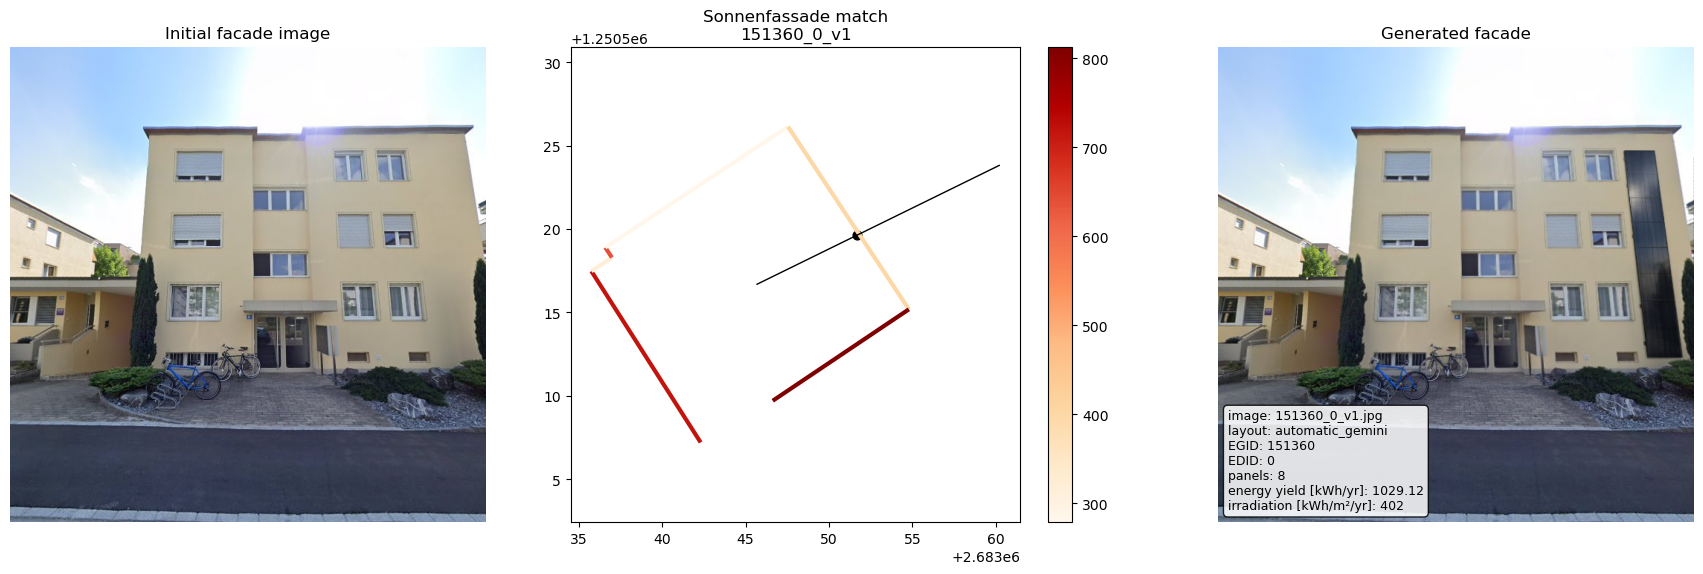

In [29]:
# Example usage
_ = visualize_building_viewline_yield_and_generated_facade(
    solar_df=solar_df,
    facade_matches=facade_matches_unique,
    gdf=gdf,
    image_stem="151360_0_v1",
    variant="automatic_gemini",
)